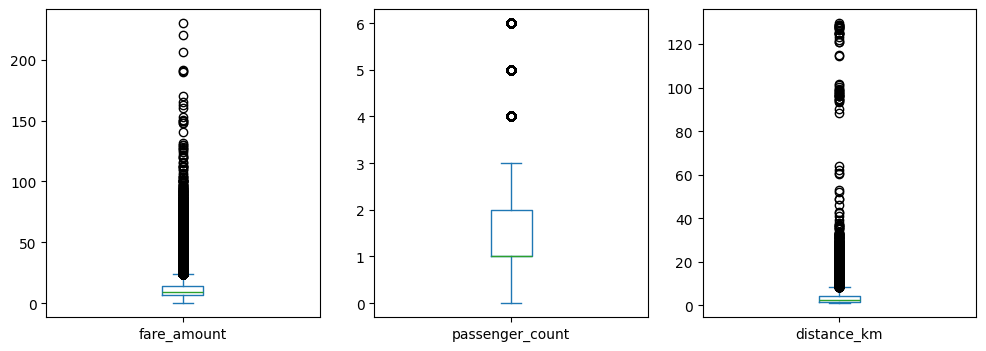

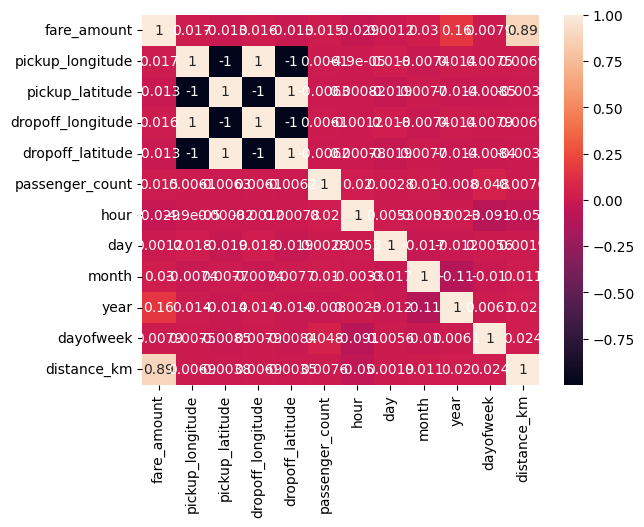


 Linear Regression
R2 Score: 0.812
RMSE: 2.48

 Ridge Regression
R2 Score: 0.812
RMSE: 2.48

 Lasso Regression
R2 Score: 0.811
RMSE: 2.487


In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

# 2. Load dataset
df = pd.read_csv("uber.csv")

# 3. Remove unnecessary columns
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

# 4. Preprocess data
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce")
df = df.dropna()

# 5. Extract date and time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["dayofweek"] = df["pickup_datetime"].dt.dayofweek

# 6. Calculate distance using Haversine formula
def distance(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df["distance_km"] = distance(
    df["pickup_longitude"], df["pickup_latitude"],
    df["dropoff_longitude"], df["dropoff_latitude"]
)

# 7. Remove invalid data
df = df[
    df["pickup_latitude"].between(-90, 90) &
    df["dropoff_latitude"].between(-90, 90) &
    df["pickup_longitude"].between(-180, 180) &
    df["dropoff_longitude"].between(-180, 180) &
    df["distance_km"].between(1, 130) &
    df["fare_amount"].between(0, 500)
].copy()

df = df.drop(columns=["pickup_datetime"])

# 8. Identify outliers using boxplots
df[["fare_amount", "passenger_count", "distance_km"]].plot(
    kind="box", subplots=True, layout=(1, 3), figsize=(12, 4)
)
plt.show()

# 9. Treat outliers using IQR
for col in ["fare_amount", "passenger_count", "distance_km"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col] = df[col].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

# 10. Check correlation
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

# 11. Split data into input and output
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 12. Create regression models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000)
}

# 13. Train and evaluate models
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    r2 = r2_score(y_test, prediction)
    rmse = np.sqrt(mean_squared_error(y_test, prediction))

    print("\n", name)
    print("R2 Score:", round(r2, 3))
    print("RMSE:", round(rmse, 3))